## Time Series Grid SANOS Market Generation Test: State 10

This notebook computes historic time series for implied vols, fitting error, DLV vs a gixed NMS grid.



In [1]:

import os
os.environ["JAX_ENABLE_X64"] = "True"

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.sanos.sanos_tools
%aimport quantdata.sanos.arbfree
%aimport quantdata.sanos.sanos
%aimport quantdata.dysanos.grid.interpolated
%aimport quantdata.dysanos.grid.torch_load
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 

from quantdata.dysanos.grid.torch_load import load, date
r_nms = load("nms", start=date(2020,1,1))
print(f"nms /done - found {len(r_nms.ts['dates'])} dates.")
    

nms /done - found 1412 dates.


00: Training long_std version 0.1 for 100000 epochs on SPX for date range 2020-01-01_2025-08-30x
00: Using all samples with learning rate 0.001 and weight decay 0.0001.
01:   Model config: 0.25-smooth@10 midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=200,a=ReLU,b=True)
01:   Grid config: nms,rg=(-2,1),nm=20,xp=(2.0,4.9,9.9,39.5,126.0,252.0);sth=0.25,mid=0.01,mxd=2
01:   Mk Arb Free pre-processor: surface,mhs=0.0001,mw=0.10,mav=0.05,mik=5,mdn=0.0001,dC=0.001,dps=0.0001
01:   Options filter: nopt=1000,bdte=756,nmsat=(-5.0, 2.0),lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   Raw day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
00: Preparing data set long_std version 0.1 for 0.25-smooth@10 midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=200,a=ReLU,b=True) traing TrainConfig(num_epochs=100000, lr=0.001, weight_decay=0.0001, batch_size=None) on Env(prec=32,device=cuda,debug=False)... done; this took 0.44s.
00: Instantiating long_std version 0.1 for 0

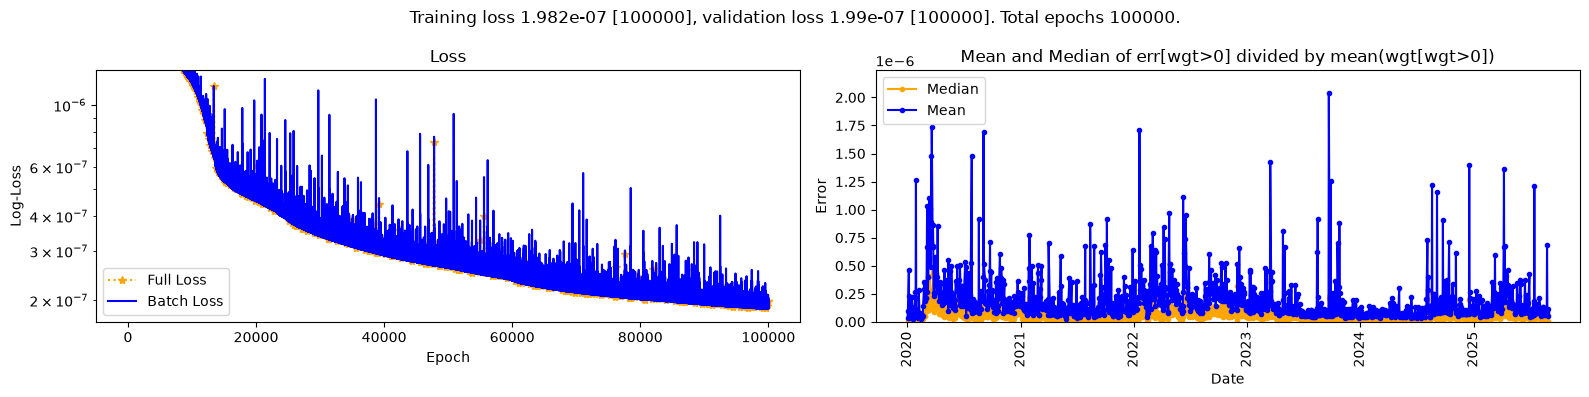

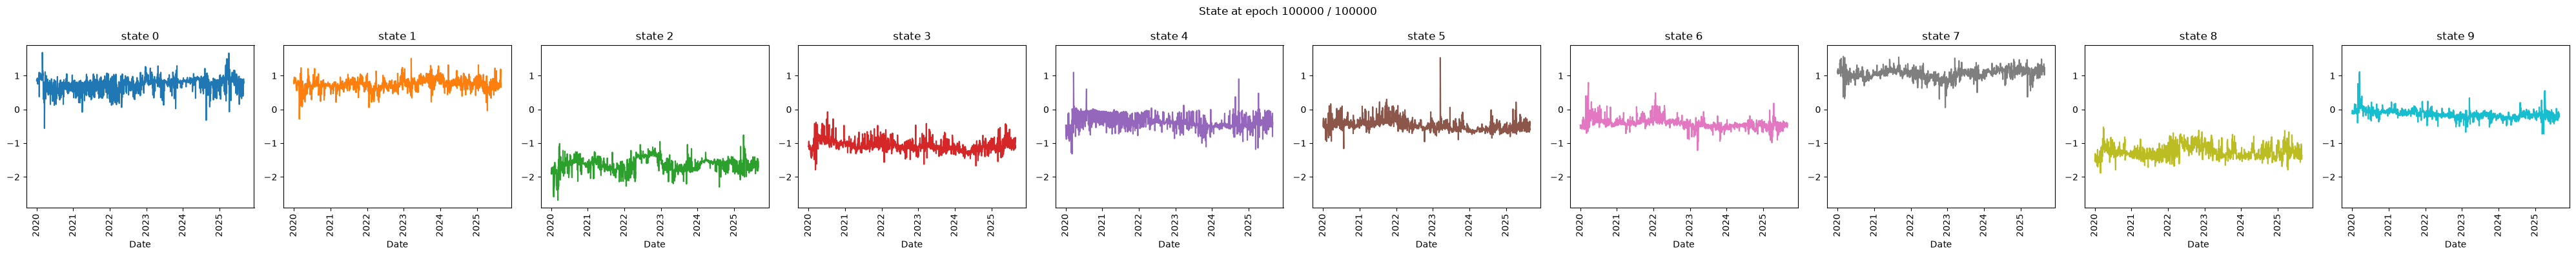

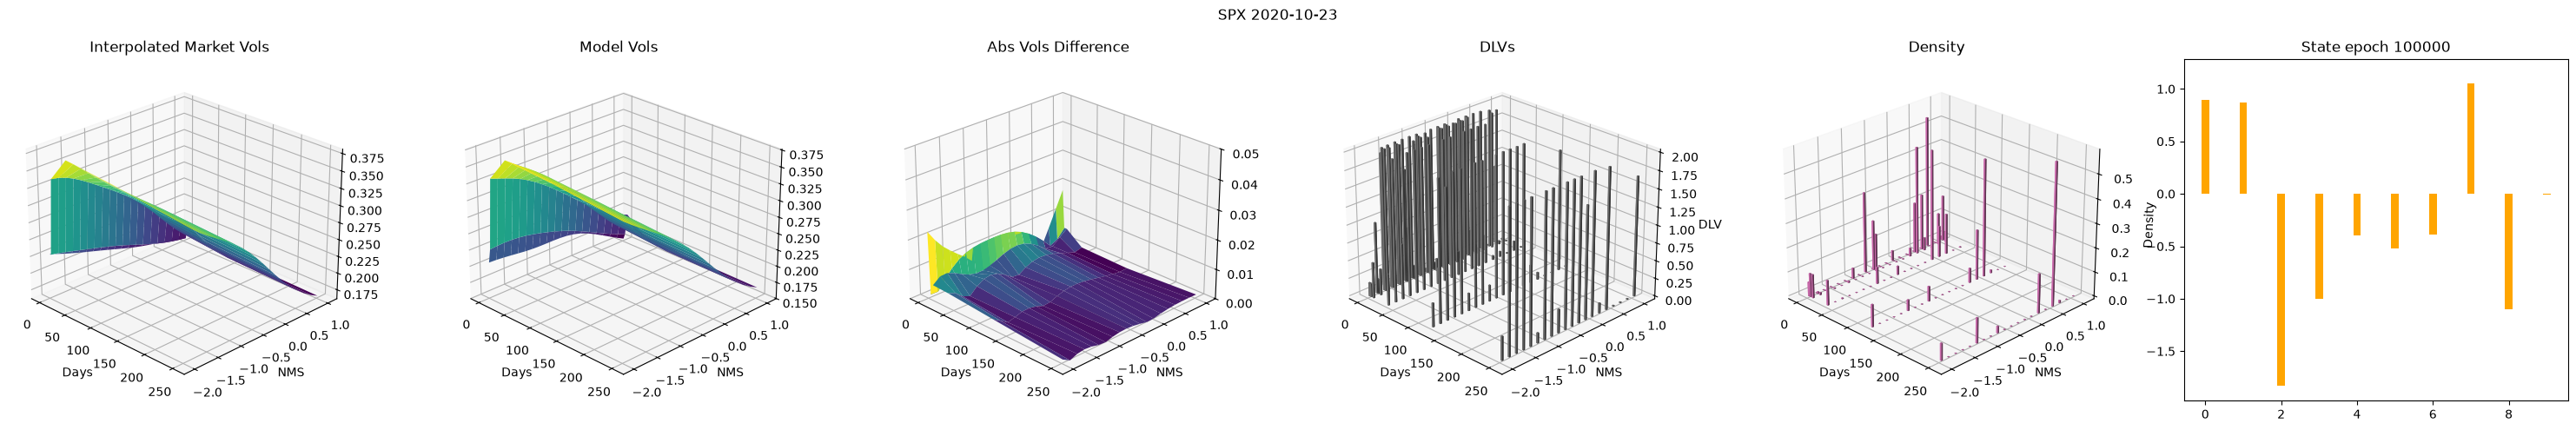

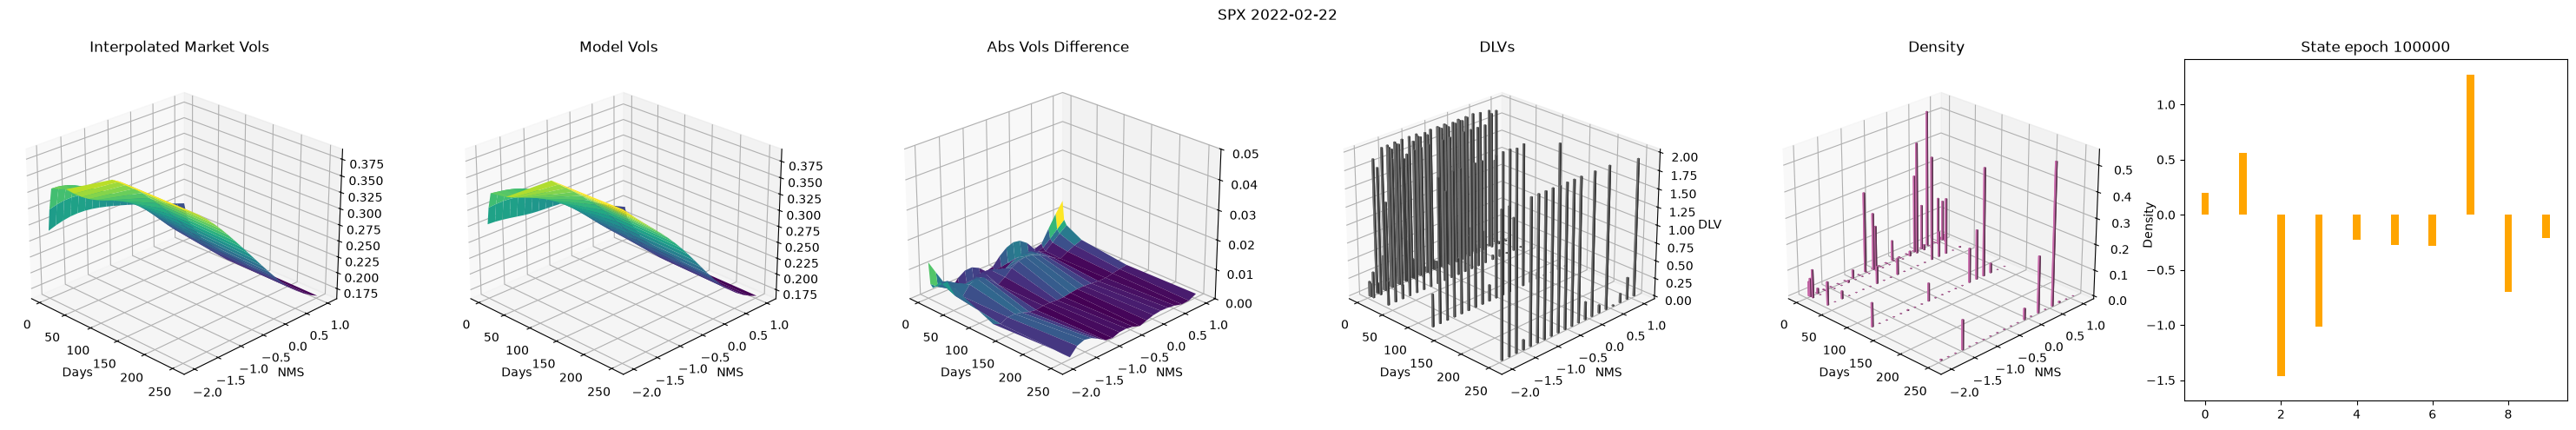

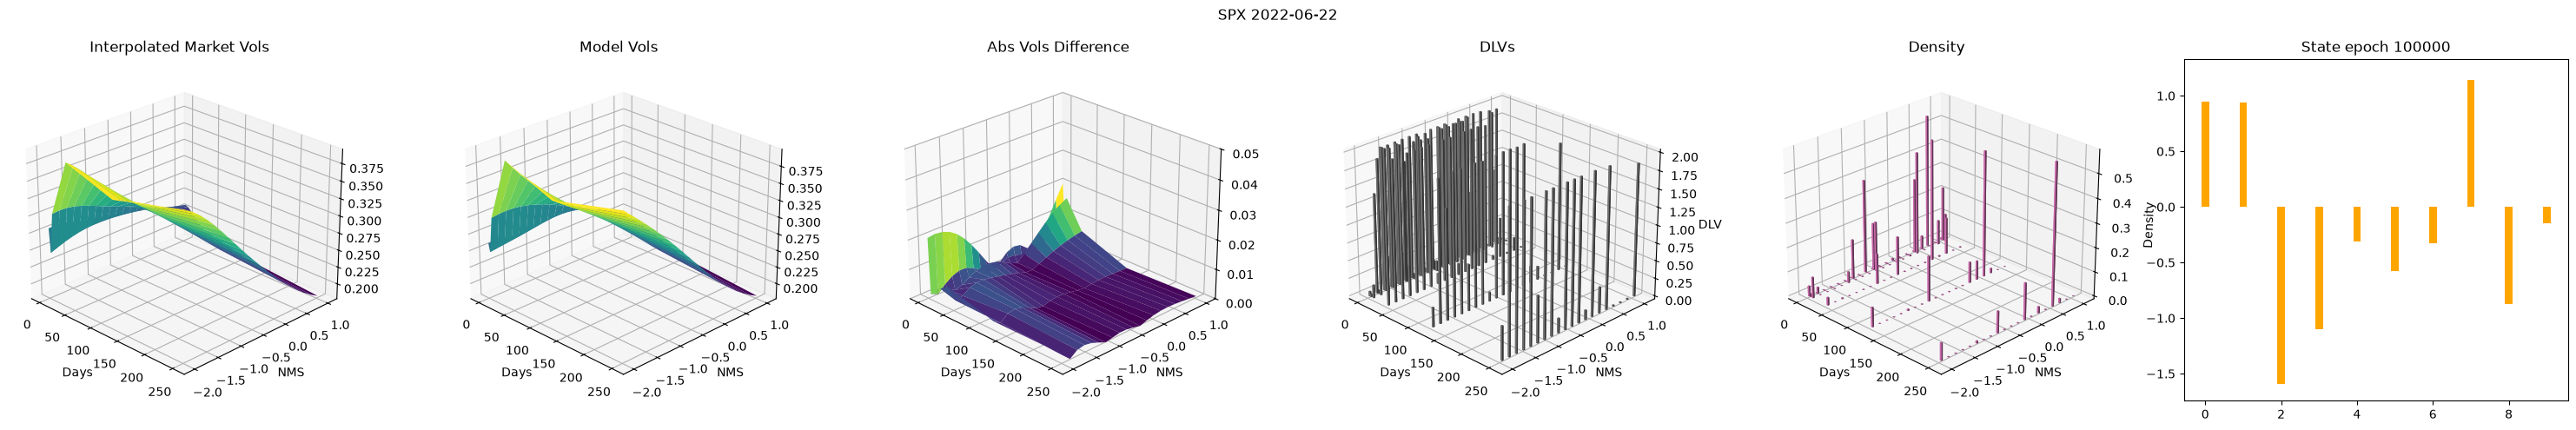

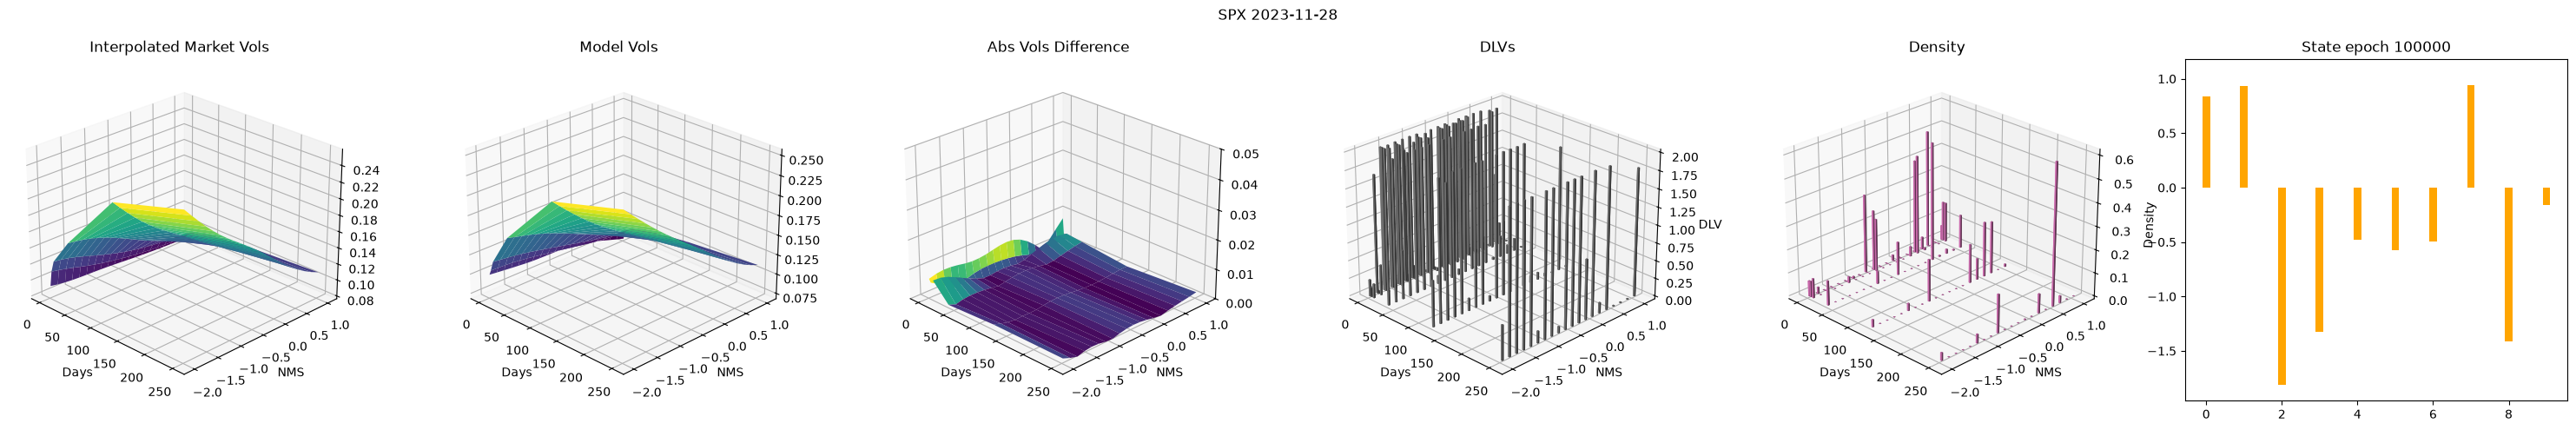

00: Training 0.25-smooth@10 midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=200,a=ReLU,b=True) with TrainConfig(num_epochs=100000, lr=0.001, weight_decay=0.0001, batch_size=None) on Env(prec=32,device=cuda,debug=False):
01:   Epoch 27000/100000, Loss: 3.776e-07. So far this took 2s.   

/home/hans/vqdata/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


01:   Epoch 27000/100000, Loss: 3.776e-07. Valuation loss: 3.762e-07. So far this took 4s. [Check point saved]
01:   Epoch 27200/100000, Loss: 3.627e-07. Valuation loss: 3.609e-07. So far this took 15s. [Check point saved]
01:   Epoch 27400/100000, Loss: 3.67e-07. Valuation loss: 3.59e-07. So far this took 27s. [Check point saved]
01:   Epoch 27600/100000, Loss: 3.82e-07. Valuation loss: 3.824e-07. So far this took 38s. [Check point saved]
01:   Epoch 27800/100000, Loss: 3.991e-07. Valuation loss: 4.019e-07. So far this took 50s. [Check point saved]
01:   Epoch 28000/100000, Loss: 3.552e-07. Valuation loss: 3.539e-07. So far this took 1:02. [Check point saved]
01:   Epoch 28200/100000, Loss: 3.594e-07. Valuation loss: 3.56e-07. So far this took 1:14. [Check point saved]
01:   Epoch 28400/100000, Loss: 3.656e-07. Valuation loss: 3.703e-07. So far this took 1:27. [Check point saved]
01:   Epoch 28600/100000, Loss: 3.574e-07. Valuation loss: 3.63e-07. So far this took 1:38. [Check point s

In [2]:
from cdxcore.bs import bs
from flax.nnx import state

from quantdata.biz_calendar import DAYS_PER_YEAR
from quantdata.dysanos.grid.torch_model import BaseEnvironment, SanosCompressorConfig, SanosCompressor, FeedForward, torch
from dataclasses import dataclass
import numpy as np
from cdxcore.dynaplot import FigStore, colors_tableau, figure, m_o_m
from quantdata.dysanos.grid.torch_gfx import Display
from quantdata.dysanos.grid.torch_train import train, TrainConfig

mdl_config = SanosCompressorConfig( 
    label="long_std",
    smoothness = 0.25,
    num_state = 10, 
    state_config = FeedForward.Config(
        activation = "ReLU",
        num_depth = 2,
        num_width = 200,
        use_bias = True,
    ),
    learn_config = None,
    state_common_init = True
)

trn_config = TrainConfig( num_epochs=100000, lr=1E-3, weight_decay=1e-4 )
r = train( r_nms, mdl_config=mdl_config, trn_config=trn_config, num_viz_dates=4  )
print("/done")
